In [157]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from itertools import combinations

In [158]:
# Load Datsets
def load_images(class_folder, img_size=(64, 64)):
    X = []

    for file in os.listdir(class_folder):
        img_path = os.path.join(class_folder, file)

        # Read image (RGB)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        # Resize -> not necessary for ORB/SIFT but more robust+faster processing
        #img = cv2.resize(img, img_size) # Resizing led to worse quality images with fewer keypoints

        X.append(img)

    return X

In [159]:
X_train = load_images("Datasets/dataset_1/group_5-15")

### Phase 1: Grouping images into regions

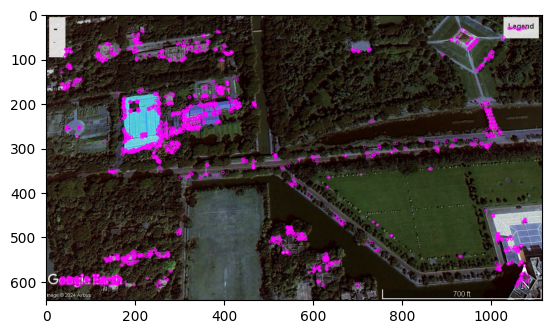

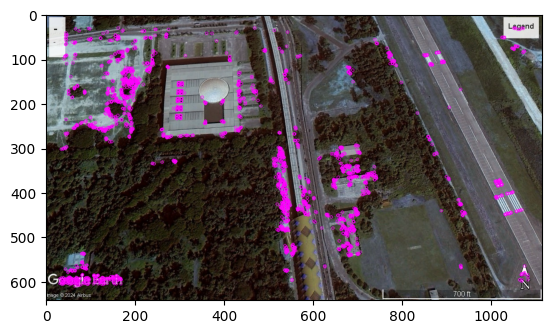

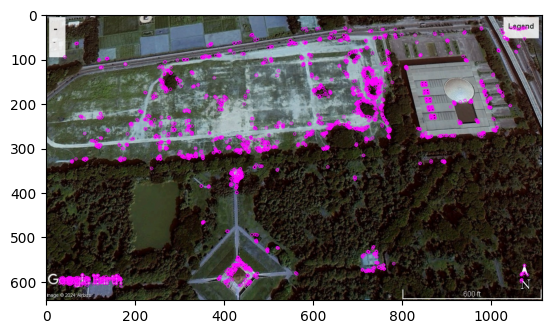

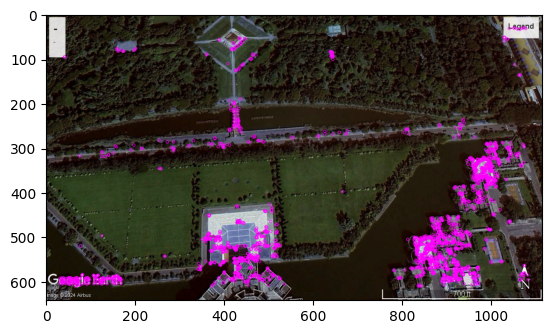

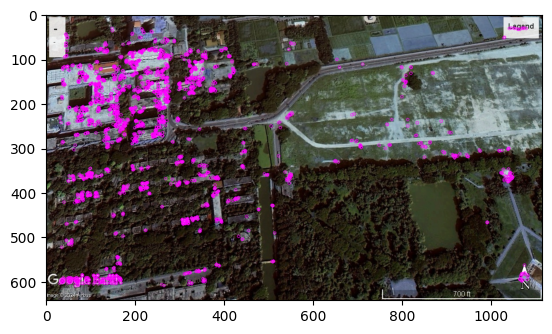

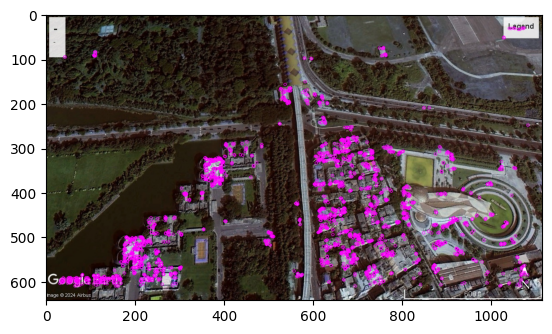

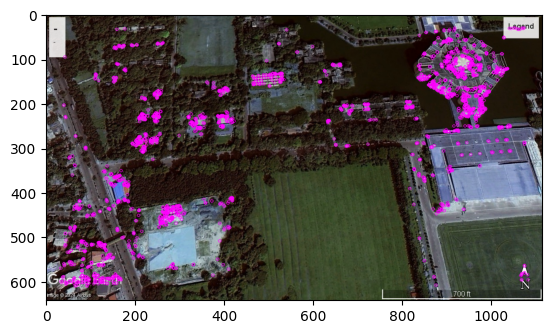

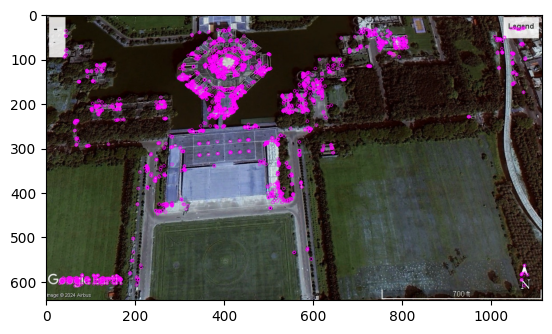

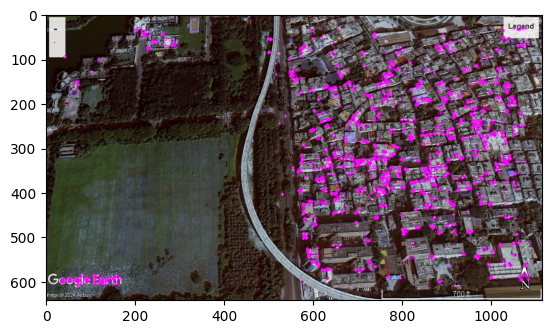

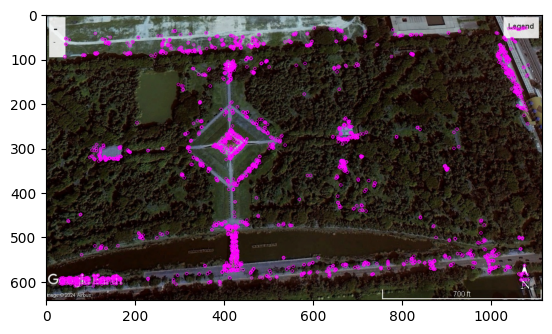

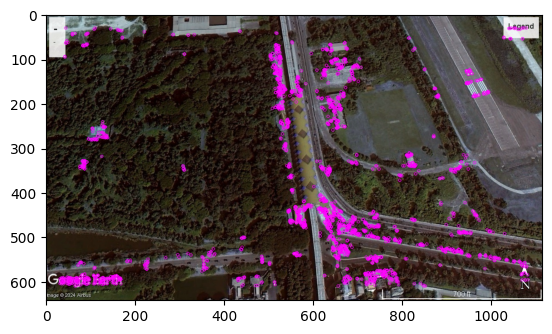

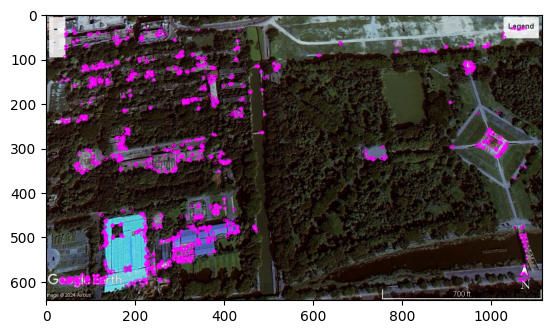

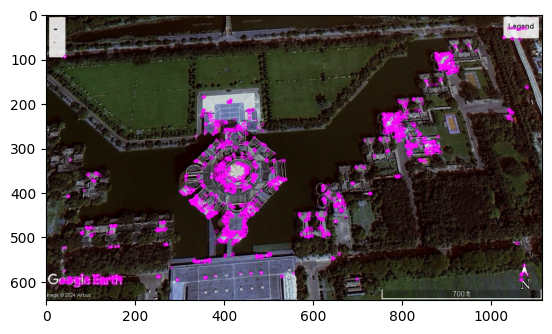

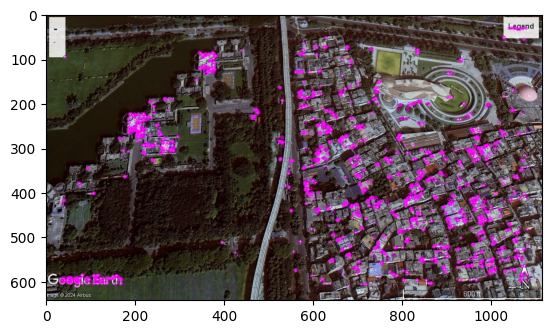

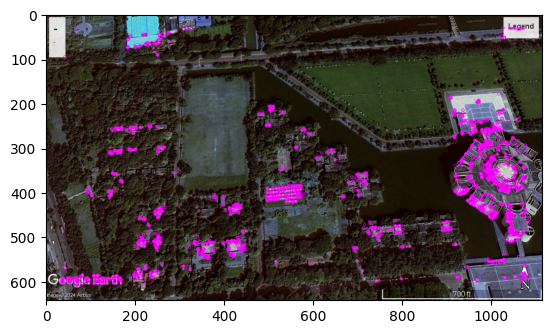

In [160]:
# Extract local features from every image - ORB

features = []
orb = cv2.ORB_create(nfeatures=2500)
# increasing number of matches from 500(default) to 1000 to 1500 to 2000 to 2500 increased final matches from 31 to 34 to 41 to 47 to 54 -> little effect

for img in X_train:

    kp = orb.detect(img,None)
    kp, des = orb.compute(img, kp)
    features.append((kp, des))

    img2 = cv2.drawKeypoints(img, kp, None, color=(255,0,255), flags=0)
    plt.imshow(img2), plt.show()

In [161]:
# Match features between all image pairs (BFMatcher for Hamming distance) 
# + Lowe's ratio test to remove false/ambigious matches 
# + Build a similarity graph

def build_similarity_graph(features, ratio_threshold=0.75, min_matches=10):
    G = nx.Graph()
    n_images = len(features)

    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

    for i, j in combinations(range(len(X_train)), 2):
        img1, (kp1, des1) = X_train[i], features[i]
        img2, (kp2, des2) = X_train[j], features[j]
        
        # Skip if one image has no descriptors
        if des1 is None or des2 is None:
            continue

        # Use knnMatch to find the two best matches for each descriptor
        matches = bf.knnMatch(des1, des2, k=2)  # k=2 to get the two best matches

        # Apply Lowe's Ratio Test to filter out ambiguous matches
        filtered_matches = []
        for m, n in matches:
            if m.distance < 0.75 * n.distance:  # Lowe's ratio test
                filtered_matches.append(m)

        num_filtered = len(filtered_matches)

        # Build Graph Edge if enough matches
        if num_filtered >= min_matches:
            # Use number of matches or inverse of distance as edge weight
            G.add_edge(i, j, weight=num_filtered)
    
    print("Number of matches after filtering: ",num_filtered)
    print("Number of edges (similar pairs):", G.number_of_edges())

    return G

Number of matches after filtering:  35
Number of edges (similar pairs): 105


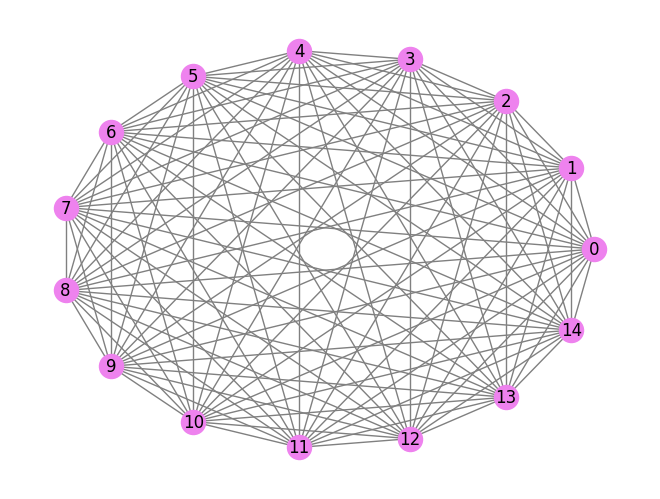

In [ ]:
# Display simililarity graph (NetworkX)

graph = build_similarity_graph(features)
nx.draw(graph,
        pos=nx.circular_layout(graph),
        with_labels=True,
        node_color='violet', 
        edge_color='gray')
plt.show()

In [163]:
# Cluster the graph


### Phase 2: Image Stitching

In [164]:
# Detect keypoints (ORB/SIFT) + match descriptors + RANSAC + warp images + blend


In [165]:
# Convert to 2D map


In [166]:
# Road segmentation


In [167]:
# Shortest Path (Djikstra or A*)
